# Point-M2AE — multiple-iteration reconstruction with configurable mask ratio

Run top to bottom using the **Point-M2AE (CUDA 12.4)** kernel (`pointm2ae` environment),
the same environment as `Point2MAE_reconstruction.ipynb`.
The former `landslide-research` / square-grid model is no longer used here.

`ITERATIONS` counts repeated groups of `PASSES_PER_ITERATION` ordinary Point-M2AE
masking passes. **These are not complete coverage sweeps.** Coverage measures the
model's middle-level hierarchy patches, not grid cells or individual input points.
The existing masking implementation always exposes middle-level center zero, so
100% coverage is not expected. More passes/iterations may increase coverage.

The pipeline retains **only the first masked prediction for each patch across
all passes and iterations**. Later predictions of that patch are discarded.
A second cloud summarizes only the retained predictions with `voxel`, `nn`, or `ot`. **Neither exported cloud contains original
LAS points.** The source supplies model input/context and is displayed for comparison.
Each pass uses the original preprocessed cloud; predictions are not fed back in.

`LIMIT = None` processes every matching file. Set it to `1` to try one unit first.
Each run needs a new output directory. No training is performed.

In [29]:
from datetime import datetime, timezone
from pathlib import Path
import csv
import json
import sys
import uuid

PROJECT_ROOT = next(
    (candidate for candidate in (Path.cwd(), *Path.cwd().parents)
     if (candidate / 'point2mae_reconstruction.py').is_file()
     and (candidate / 'LS_Slopes_reconstruction_Multiple_iterations').is_dir()), None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Start the kernel in the project root or a folder below it.')
RECONSTRUCTION_DIR = PROJECT_ROOT / 'LS_Slopes_reconstruction_Multiple_iterations'
for folder in (PROJECT_ROOT, RECONSTRUCTION_DIR):
    if str(folder) not in sys.path:
        sys.path.insert(0, str(folder))

import laspy
import matplotlib.pyplot as plt
import numpy as np
from reconstruct_slopes import DEFAULT_CHECKPOINT, DEFAULT_INPUT, DEFAULT_MODEL_ROOT, run_pipeline

print('Project:', PROJECT_ROOT)
print('Python:', sys.executable)

Project: /home/khan365/Point-M2AE-main
Python: /home/khan365/miniconda3/envs/pointm2ae/bin/python


## Configure the run

Use a full `best.pt` or `last.pt` from `Point2MAE_training.ipynb`. Architecture,
grouping, and normalization come from the checkpoint. SquareGridSUMAE checkpoints are incompatible.

Set `MASK_RATIO = 0.8` to mask 80% of the **top-level patches** per pass
(before integer rounding). Use `None` to use the checkpoint ratio. Values must
be strictly between 0 and 1. The ratio applies to every pass and iteration;
middle-level prediction coverage can differ because masks propagate through the hierarchy.
Some low ratios cannot leave both masked reconstruction targets and enough visible
neighbours for a given cloud; those units are reported in `failures.csv`.
Changing the inference ratio does not retrain the model or edit the checkpoint.
The manifest stores the effective ratio in `run_config.model.mask_ratio` and both
the training and inference ratios in `checkpoint_info`.

`ITERATIONS = 2` and `PASSES_PER_ITERATION = 8` make **16 forward passes per unit**.
All inputs are retained for inference; a full unit must fit in CUDA memory.
`SEED` controls reproducible per-file/iteration seeds; each pass advances its
iteration's random sequence. Adding files or changing `LIMIT` does not change a
file's seed. The batch seed is derived from its relative path, so it differs from
the single-cloud notebook's seed with the same displayed integer.

`nn` assigns predictions to first-set anchors within each predicted patch;
`ot` uses one-to-one optimal assignments before averaging; `voxel` computes one
mean per occupied output voxel. NN/OT only include patches actually predicted. With one retained prediction
set per patch, NN/OT leave its geometry unchanged; voxel can still reduce points.
For `voxel`, `VOXEL_SIZE = None` means **0.5 source coordinate units** (meters if
the source CRS uses meters). Point-M2AE has no fixed training grid spacing.
Use `SOURCE_GLOB = '*'` to include both LAS and LAZ; LAZ requires a laspy backend.

In [ ]:
INPUT_DIR = '/home/khan365/Point-M2AE-main/Output/full_20261006_001322_611477/LS_head_scarp_Slope_units/UTU'
CHECKPOINT = DEFAULT_CHECKPOINT
MODEL_ROOT = DEFAULT_MODEL_ROOT
OUTPUT_DIR = RECONSTRUCTION_DIR / 'results' / (
    'pointm2ae_recon_97M_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ')
    + '_' + uuid.uuid4().hex[:8]
)
ITERATIONS = 1
PASSES_PER_ITERATION = 3
MASK_RATIO = 0.9  # Fraction masked at the top scale; None uses the checkpoint ratio.
REPRESENTATIVE_METHOD = 'nn'  # 'voxel', 'nn', or 'ot'
VOXEL_SIZE = None  # Only for voxel; None means 0.5 source coordinate units.
LIMIT = 5  # None processes every matching file.
SOURCE_GLOB = '*.las'  # Example: 'UTU/SU_9044.las'; '*' includes LAS and LAZ.
CUDA_DEVICE = 0
SEED = 42
PLOT_MAX_POINTS = 100000  # Display only; exports contain every prediction.

print('Input:', INPUT_DIR)
print('Checkpoint:', CHECKPOINT)
print('Requested mask ratio:', MASK_RATIO if MASK_RATIO is not None else 'checkpoint default')
print('New output:', OUTPUT_DIR)
print('Total passes per unit:', ITERATIONS * PASSES_PER_ITERATION)

Input: /home/khan365/Point-M2AE-main/Output/full_20261006_001322_611477/LS_head_scarp_Slope_units/UTU
Checkpoint: /home/khan365/Point-M2AE-main/training_runs/pointm2ae_xy_20261030T190853Z_d323ddc4/best.pt
Requested mask ratio: 0.97
New output: /home/khan365/Point-M2AE-main/LS_Slopes_reconstruction_Multiple_iterations/results/pointm2ae_recon_97M_20261031T171128Z_4ce051bf
Total passes per unit: 3


## Run Point-M2AE inference and export

The shared loader strictly loads the checkpoint. `model.eval()` freezes dropout
and BatchNorm; `eval=False` in the model forward keeps masked reconstruction active.
Temporary hooks capture the same decoder predictions as `Point2MAE_reconstruction.ipynb`.
Like that notebook, **only the first prediction per patch** is retained.
The selection does not reset between iterations. Distinct patches can still
overlap spatially; this is patch selection, not coordinate deduplication.

Outputs include pass NPZ archives, a combined NPZ, both predicted-only clouds in
LAS/PLY, and manifest/summary/failure reports. XYZ coordinates are restored using
the saved centroid and scale. Source coordinate precision and CRS are retained;
measured intensity, classifications, returns, and timestamps are not copied.
Failed units are recorded and are not counted as reconstructed. Existing output
directories are refused; rerun the settings cell to create a new directory.

In [31]:
manifest = run_pipeline(
    INPUT_DIR, CHECKPOINT, OUTPUT_DIR, model_root=MODEL_ROOT,
    iterations=ITERATIONS, passes_per_iteration=PASSES_PER_ITERATION, mask_ratio=MASK_RATIO,
    representative_method=REPRESENTATIVE_METHOD, voxel_size=VOXEL_SIZE,
    limit=LIMIT, source_glob=SOURCE_GLOB, cuda_device=CUDA_DEVICE, seed=SEED,
)
REPRESENTATIVE_METHOD = manifest['representative_method']
output_root = Path(manifest['output_dir'])
print('Effective mask ratio:', manifest['run_config']['model']['mask_ratio'])
print('Checkpoint mask ratio:', manifest['checkpoint_info']['checkpoint_mask_ratio'])
print('Results:', output_root)
print('Counts:', manifest['counts'])

2026-10-31 13:11:41,861 - Point_M2AE - INFO - [Point_M2AE]


Point-M2AE: 5 units, 1 iterations x 3 passes; first prediction per patch; nn representative
Reconstructing SU_4557.las
  Iteration 1/1: 1471/1472 middle patches (99.9%), 3 passes
Reconstructing SU_4712.las
  Iteration 1/1: 576/577 middle patches (99.8%), 3 passes
Reconstructing SU_4713.las
  Iteration 1/1: 508/509 middle patches (99.8%), 3 passes
Reconstructing SU_4789.las
  Iteration 1/1: 477/478 middle patches (99.8%), 3 passes
Reconstructing SU_4793.las
  Iteration 1/1: 667/668 middle patches (99.9%), 3 passes
Effective mask ratio: 0.97
Checkpoint mask ratio: 0.8
Results: /home/khan365/Point-M2AE-main/LS_Slopes_reconstruction_Multiple_iterations/results/pointm2ae_recon_97M_20261031T171128Z_4ce051bf
Counts: {'selected': 5, 'reconstructed': 5, 'failed': 0}


## Check actual coverage and point counts

`coverage_counts[iteration, patch]` counts masked predictions, including repeated
predictions. Zeros mean the patch was not reconstructed in that iteration.
Overall coverage is the union across iterations; **incomplete coverage is valid**.
This is patch coverage, not a guarantee that all raw input geometry was recovered.
`representative_counts` sums to the number of **retained** points for every method.
`retained_patch_counts` records how many new patches each pass contributes;
`masked_patch_counts` and `coverage_counts` still describe all inference attempts.
The reported Chamfer value is a masked-patch score in model-coordinate units squared,
not a full-cloud error. Exported NPZ/LAS/PLY coordinates use source units.

In [32]:
with (output_root / 'summary.csv').open(newline='', encoding='utf-8') as stream:
    rows = list(csv.DictReader(stream))
if manifest['counts']['failed']:
    raise RuntimeError(f"{manifest['counts']['failed']} units failed; inspect {output_root / 'failures.csv'}")
if not rows or len(rows) != manifest['counts']['reconstructed']:
    raise RuntimeError('Summary and manifest reconstructed counts do not agree')
for row in rows:
    with np.load(output_root / row['combined_file'], allow_pickle=False) as archive:
        coverage = archive['coverage_counts']
        all_xyz = archive['all_predicted_xyz']
        representative_xyz = archive['representative_xyz']
        assert coverage.shape == (ITERATIONS, int(row['patch_count']))
        assert all_xyz.shape == (int(row['all_predicted_points']), 3)
        assert representative_xyz.shape == (int(row['representative_points']), 3)
        assert np.isfinite(all_xyz).all() and np.isfinite(representative_xyz).all()
        assert archive['prediction_selection'].item() == 'first_per_patch'
        covered_ids = np.flatnonzero((coverage > 0).any(axis=0))
        assert int(archive['retained_patch_counts'].sum()) == len(covered_ids)
        ids, counts = np.unique(archive['patch_ids'], return_counts=True)
        assert np.array_equal(ids, covered_ids)
        assert np.all(counts == counts[0])
        assert int(archive['representative_counts'].sum(dtype=np.uint64)) == len(all_xyz)
        assert np.isclose((coverage > 0).any(axis=0).mean(), float(row['coverage_fraction']))
        assert np.allclose((coverage > 0).mean(axis=1), json.loads(row['coverage_by_iteration']))
        assert int(archive['masked_patch_counts'].sum()) == int(coverage.sum())
        assert len(archive['masked_patch_counts']) == ITERATIONS * PASSES_PER_ITERATION
        if REPRESENTATIVE_METHOD == 'voxel':
            assert archive['representative_patch_ids'].size == 0
        else:
            assert np.array_equal(np.unique(archive['representative_patch_ids']),
                                  np.flatnonzero((coverage > 0).any(axis=0)))
    assert int(row['total_passes']) == ITERATIONS * PASSES_PER_ITERATION
    print(f"{row['source_file']}: coverage {float(row['coverage_fraction']):.1%}; "
          f"per iteration {row['coverage_by_iteration']}; "
          f"{row['all_predicted_points']} predictions -> {row['representative_points']} representatives")

SU_4557.las: coverage 99.9%; per iteration [0.9993206521739131]; 11768 predictions -> 11768 representatives
SU_4712.las: coverage 99.8%; per iteration [0.9982668977469671]; 4608 predictions -> 4608 representatives
SU_4713.las: coverage 99.8%; per iteration [0.9980353634577603]; 4064 predictions -> 4064 representatives
SU_4789.las: coverage 99.8%; per iteration [0.997907949790795]; 3816 predictions -> 3816 representatives
SU_4793.las: coverage 99.9%; per iteration [0.9985029940119761]; 5336 predictions -> 5336 representatives


## Compare the source and the two predicted-only clouds

The first successful source is shown in X–Z and Y–Z projections with common limits
calculated from the full clouds. Sampling affects display only. Original points
appear only in the comparison panels. Change display settings and rerun this cell
without running inference again.

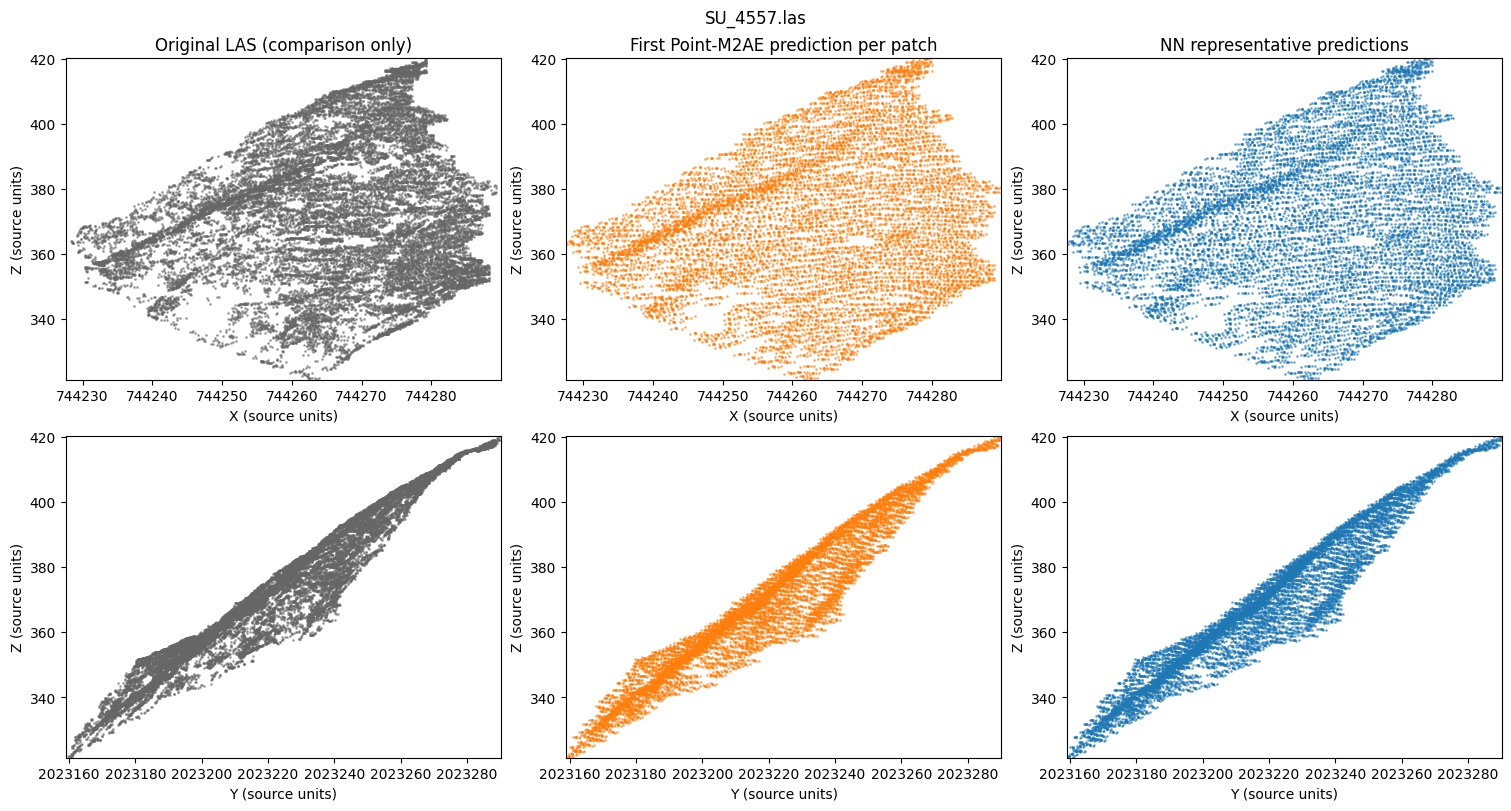

First predictions: /home/khan365/Point-M2AE-main/LS_Slopes_reconstruction_Multiple_iterations/results/pointm2ae_recon_97M_20261031T171128Z_4ce051bf/point_clouds/SU_4557_first_predictions.las
Representative: /home/khan365/Point-M2AE-main/LS_Slopes_reconstruction_Multiple_iterations/results/pointm2ae_recon_97M_20261031T171128Z_4ce051bf/point_clouds/SU_4557_representative.las


In [33]:
selected = rows[0]
source_path = Path(manifest['input_dir']) / selected['source_file']
source_las = laspy.read(source_path)
original_xyz = np.column_stack((source_las.x, source_las.y, source_las.z))
with np.load(output_root / selected['combined_file'], allow_pickle=False) as archive:
    all_xyz = archive['all_predicted_xyz'].copy()
    representative_xyz = archive['representative_xyz'].copy()

if type(PLOT_MAX_POINTS) is not int or PLOT_MAX_POINTS < 1:
    raise ValueError('PLOT_MAX_POINTS must be a positive integer')
generator = np.random.default_rng(SEED)
def display_subset(xyz):
    if len(xyz) <= PLOT_MAX_POINTS:
        return xyz
    return xyz[generator.choice(len(xyz), PLOT_MAX_POINTS, replace=False)]

panels = [
    ('Original LAS (comparison only)', display_subset(original_xyz), '0.4'),
    ('First Point-M2AE prediction per patch', display_subset(all_xyz), 'tab:orange'),
    (f'{REPRESENTATIVE_METHOD.upper()} representative predictions', display_subset(representative_xyz), 'tab:blue'),
]
fig, axes = plt.subplots(2, 3, figsize=(15, 8), constrained_layout=True)
for row_index, (coordinate, label) in enumerate(((0, 'X'), (1, 'Y'))):
    horizontal_min = min(points[:, coordinate].min() for points in (original_xyz, all_xyz, representative_xyz))
    horizontal_max = max(points[:, coordinate].max() for points in (original_xyz, all_xyz, representative_xyz))
    vertical_min = min(points[:, 2].min() for points in (original_xyz, all_xyz, representative_xyz))
    vertical_max = max(points[:, 2].max() for points in (original_xyz, all_xyz, representative_xyz))
    for column, (title, points, color) in enumerate(panels):
        ax = axes[row_index, column]
        ax.scatter(points[:, coordinate], points[:, 2], s=1, c=color, alpha=0.5, rasterized=True)
        ax.set_xlim(horizontal_min, horizontal_max)
        ax.set_ylim(vertical_min, vertical_max)
        ax.set_xlabel(f'{label} (source units)')
        ax.set_ylabel('Z (source units)')
        ax.ticklabel_format(useOffset=False, style='plain')
        if row_index == 0:
            ax.set_title(title)
fig.suptitle(selected['source_file'])
plt.show()
print('First predictions:', output_root / selected['all_las_file'])
print('Representative:', output_root / selected['representative_las_file'])